# Fractional PDE discovery for the ensemble-average fields

In [1]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.
# Method reference for fractional equation discovery by symbolic regression and stochastic optimization:
# Im, de Barros, Masri, Sahimi & Ziff (2023), Phys. Rev. E 107, L013301, https://doi.org/10.1103/PhysRevE.107.L013301.
# The authors' GPfSI reference code is at https://github.com/Jinwoousc/GPSI.
# The search here uses a poroelastic candidate library and scores its own forward solves.
# Spatial stencils come from the archived B-RefStruct solver (GPL-3.0-or-later).
# See src/fpde/spatial_kernels.py for stencil references and src/fpde/LICENSE for the license.

import sys
import subprocess
from html import escape
from pathlib import Path

RUN_MODE = "saved"
LOCAL_WORKERS = 1
CARC_PARTITION = "jha"
CARC_ACCOUNT = None
RESUME_CARC = False

if RUN_MODE not in {"saved", "frozen", "local", "carc"}:
    raise ValueError("Use saved, frozen, local or carc.")
ROOT = Path.cwd().resolve()
SRC = ROOT / "src/fpde"
ASSETS = ROOT / "assets/fpde"
DATA = ROOT / "data/443EA_CLEAN_ICSTRAIN0.1_P_U1_U2.npz"
OUT = ROOT / "outputs/fpde"
if not DATA.is_file():
    raise FileNotFoundError(DATA)
sys.path.insert(0, str(SRC))
from runtime import load_json
from candidates import equations
from IPython.display import display, HTML, Image
import numpy as np
import matplotlib.pyplot as plt
import evaluation_6935953 as ev

TRAIN = RUN_MODE in {"local", "carc"}
if TRAIN:
    from runtime import clean_env, save_json
    from submit import parser, create_config

    SEARCH = OUT / ("discovery_classical_" + RUN_MODE)
    ENV = clean_env()
    ENV["PYTHONHASHSEED"] = "0"

Matplotlib is building the font cache; this may take a moment.


In [2]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if TRAIN:
    COARSE_WORKERS = 64 if RUN_MODE == "carc" else LOCAL_WORKERS
    FINE_WORKERS = 16 if RUN_MODE == "carc" else LOCAL_WORKERS
    if RUN_MODE == "local" and not 1 <= LOCAL_WORKERS <= 16:
        raise ValueError("LOCAL_WORKERS must be between 1 and 16.")
    options = [
        "--profile", "production", "--data", str(DATA), "--outdir", str(SEARCH),
        "--python", sys.executable, "--observed-initial-output",
        "--partition", CARC_PARTITION, "--cpus", str(COARSE_WORKERS),
        "--fine-cpus", str(FINE_WORKERS), "--mem", "240G",
        "--trials", "10", "--seed", "20260922", "--population", "64",
        "--search-grid", "51", "--generations", "30", "--time-substeps", "2",
        "--final-grid", "101", "--fine-generations", "6", "--fine-time-substeps", "4",
        "--field-weights", "0.5", "0.25", "0.25", "--ic-weight", "0.5", "--ic-tolerance", "0.05",
    ]
    if CARC_ACCOUNT:
        options.extend(["--account", CARC_ACCOUNT])
    cfg = create_config(parser().parse_args(options))
    print("Discovery initialization:", cfg["initialization"])
    print("Training frames 0–38 · Evaluation frames 39–48")
    print("Coarse: 10 trials × 64 candidates × 30 generations on a 51 × 51 grid")
    print("Fine: 10 trials × 64 candidates × 6 generations on a 101 × 101 grid")
    print("Selection: classical Biot model + 10 fine-stage winners, 8 substeps on the 101 × 101 grid")
    print("Objective: 0.5(1 − R²_P) + 0.25(1 − R²_U1) + 0.25(1 − R²_U2) + 0.5 E_IC + 0.0005 N_complexity")

In [3]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

def run_stage(mode, trial=None):
    command = [sys.executable, "-u", str(SRC / "workflow.py"), "--config",
               str(SEARCH / "RUN_CONFIG.json"), "--mode", mode, "--allow-local"]
    if trial is not None:
        command.extend(["--trial", str(trial)])
    while True:
        rc = subprocess.run(command, env=ENV, cwd=SRC).returncode
        if rc == 0:
            return
        if rc != 75:
            raise subprocess.CalledProcessError(rc, command)

if RUN_MODE == "local":
    SEARCH.mkdir(parents=True, exist_ok=True)
    config_path = SEARCH / "RUN_CONFIG.json"
    if config_path.is_file() and load_json(config_path)["identity"] != cfg["identity"]:
        raise ValueError("Choose a new search directory for the changed training configuration.")
    save_json(config_path, cfg)
    run_stage("prepare")
elif RUN_MODE == "carc":
    config_path = SEARCH / "RUN_CONFIG.json"
    if config_path.is_file() and load_json(config_path)["identity"] != cfg["identity"]:
        raise ValueError("Choose a new search directory for the changed training configuration.")
    if not config_path.is_file() or (RESUME_CARC and not (SEARCH / "observed_initial/run_result.json").is_file()):
        flags = ["--resume"] if config_path.is_file() else []
        subprocess.run([sys.executable, str(SRC / "submit.py"), *options, *flags],
                       env=ENV, cwd=SRC, check=True)
    if (SEARCH / "JOB_IDS.json").is_file():
        print("Slurm jobs:", load_json(SEARCH / "JOB_IDS.json")["submissions"][-1])

In [4]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if RUN_MODE == "local":
    for trial in range(cfg["n_trials"]):
        run_stage("coarse", trial)

In [5]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if RUN_MODE == "local":
    for trial in range(cfg["n_trials"]):
        run_stage("fine", trial)

In [6]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if TRAIN:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
    have_history = False
    for ax, phase in zip(axes, ("COARSE", "FINE")):
        for trial in range(cfg["n_trials"]):
            path = SEARCH / "trials" / f"trial_{trial:02d}" / f"{phase}_HISTORY.json"
            if path.is_file():
                history = load_json(path)
                ax.plot([row["generation"] for row in history], [row["loss"] for row in history],
                        label=f"Trial {trial}")
                have_history = True
        ax.set(title=phase.capitalize(), xlabel="Generation", ylabel="Best training objective")
        ax.grid(alpha=0.2)
        if ax.lines:
            ax.legend(fontsize=7, ncol=2)
    if have_history:
        display(fig)
    plt.close(fig)

In [7]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if RUN_MODE == "local":
    run_stage("aggregate")
    run_stage("observed")

available = not TRAIN or (SEARCH / "observed_initial/run_result.json").is_file()
if not available:
    print("Results pending in", SEARCH.relative_to(ROOT))
    print("When the observed-initial job finishes, run the remaining cells again starting here.")
elif TRAIN:
    selected = load_json(SEARCH / "SELECTED_TRAINING_CANDIDATE.json")
    ic_tolerance = float(cfg["ic_tolerance"])
    result_dir = SEARCH / "observed_initial"
    candidate = selected["winner"]["candidate"]
    winner = selected["winner"]
    known_path = SEARCH / "prepared/KNOWN_INPUTS.npz"
    prediction_path = result_dir / "fpde_prediction.npz"
    forward_info = load_json(result_dir / "run_result.json")["forward"]
    print("Selected model:", selected["selected_origin"], "trial", selected["selected_trial"])
else:
    published = load_json(ROOT / "provenance/fpde.json")
    selected = published["selected"]
    ic_tolerance = float(published["config"]["ic_tolerance"])
    winner = selected["winner"]
    candidate = load_json(ASSETS / "frozen_candidate.json")
    known_path = ASSETS / "known_inputs.npz"
    result_dir = OUT / RUN_MODE
    prediction_path = ASSETS / "fpde_prediction.npz"
    forward_info = published["rerun"]
    if RUN_MODE == "frozen":
        from frozen_solver import run_forward
        prediction_path = result_dir / "fpde_prediction.npz"
        forward_info = run_forward(ASSETS, prediction_path)
    print("Published Round 4 equation, trial", selected["selected_trial"])

Published Round 4 equation, trial 9


In [8]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if available:
    with np.load(known_path, allow_pickle=False) as known:
        learned = equations(candidate, known["scales"])
        print("Field scales (Pa, m, m):", known["scales"], "| Time scale (s):", float(known["time_scale_s"]))
        print("Total well rate (m²/s):", float(known["source_total_m2_s"]))
    print("Selected objective:", winner["loss"])
    ic = np.asarray(winner["solver"]["initial_mechanics_field_relL2"])
    print("Equilibrium initial displacement error, U1/U2:", ic)
    print(f"Compatibility at {ic_tolerance:.0%} per component:", bool(ic.max() <= ic_tolerance))
    print("Observed-initial-state forward force residual:", forward_info["solver_info"]["truth_U0_force_residual"])
    for name in ("P", "U1", "U2"):
        print(name, learned[name])
    print("Orders:", candidate["orders"], learned["mechanics_orders"])
    print("Optional mechanical terms:", learned["mechanics_selection"])

Field scales (Pa, m, m): [2.00888815e+07 1.21925932e-01 7.32220742e-02] | Time scale (s): 49932000.0
Total well rate (m²/s): 6e-05
Selected objective: 0.16503103080656292
Equilibrium initial displacement error, U1/U2: [0.08078573 0.24391533]
Compatibility at 5% per component: False
Observed-initial-state forward force residual: 1.4986479417499126
P Caputo_theta^0.521942663464 P + 0.136157560052 d2U1/(dxi dtheta) + 0.0810096886335 d2U2/(deta dtheta) = 1.7574769624 FluxDiv_xi(gamma=1.65615310723,q=0.482689080775; P,gravity) + 0.558055761199 FluxDiv_eta(gamma=1.9875864331,q=0.497817660837; P,gravity) + 3196.91943165 Q
U1 +1 Q1_anchored_weak[U1_U1_x](order=1.98683480268) +0.4373381598 Q1_anchored_weak[U1_U1_y](order=2) +0.3379040573 Q1_anchored_weak[U1_U2_xy](order=2) -2.615702855 Q1_anchored_weak[U1_P_x](order=1.01992683854) = normalized Q1 gravity load
U2 +0.4373381598 Q1_anchored_weak[U2_U2_x](order=2.01807125031) +1 Q1_anchored_weak[U2_U2_y](order=2) +0.9369178608 Q1_anchored_weak[U2_U

In [9]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if available:
    paths = {"fpde": prediction_path}
    if TRAIN:
        result = load_json(result_dir / "metrics.json")
    else:
        result = ev.evaluate(ROOT, result_dir, ["fpde"], prediction_paths=paths, data_path=DATA)
        ev.plot(ROOT, result_dir, ["fpde"], prediction_paths=paths, data_path=DATA)
    computed = result["models"]["fpde"]
    print("Prediction scored:", prediction_path.relative_to(ROOT))

Fractional PDE
P train {'R2': 0.9455316122605625, 'absolute_L2': 826.201622764062, 'relative_L2': 0.06553178040951683} temporal heldout {'R2': 0.939259658183279, 'absolute_L2': 434.77126916125775, 'relative_L2': 0.06209951301268897}
Ux train {'R2': 0.9780787045117136, 'absolute_L2': 7157.5098667826205, 'relative_L2': 0.09366443839140574} temporal heldout {'R2': 0.9656991183748042, 'absolute_L2': 4972.012886868606, 'relative_L2': 0.11755770578263439}
Uy train {'R2': 0.9386932603937185, 'absolute_L2': 7409.923929282413, 'relative_L2': 0.1606316533010552} temporal heldout {'R2': 0.9060442145577261, 'absolute_L2': 5095.482934529839, 'relative_L2': 0.18328817303136155}


Figures: /private/var/folders/ky/2twj4rcs2b7fpbzw73ptl1rh0000gn/T/fpde_saved_nr8d9qx8/outputs/fpde/saved
Prediction scored: assets/fpde/fpde_prediction.npz


In [10]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if available:
    rows = []
    for period, label in [("train","Training, frames 1–38"), ("temporal_heldout","Temporal holdout, 39–48"),
                          ("last","Last frame, day 730")]:
        for name in ev.NAMES:
            field = computed["fields"][name]
            row = field[period]
            rows.append([label, name, f'{field["free_node_count"]:,}', f'{row["R2"]:.6f}',
                         f'{100 * row["relative_L2"]:.3f}%', f'{row["absolute_L2"]:.3f} {field["unit"]}'])
    headers = ("Evaluation interval", "Field", "Free nodes", "R²", "Relative L₂", "Absolute L₂")
    body = "".join("<tr>" + "".join(f"<td>{escape(v)}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML("<table><thead><tr>" + "".join(f"<th>{h}</th>" for h in headers)
                 + "</tr></thead><tbody>" + body + "</tbody></table>"))

Evaluation interval,Field,Free nodes,R²,Relative L₂,Absolute L₂
"Training, frames 1–38",P,"10,189",0.945532,6.553%,826.202 MPa
"Training, frames 1–38",Ux,"10,000",0.978079,9.366%,7157.510 mm
"Training, frames 1–38",Uy,"10,100",0.938693,16.063%,7409.924 mm
"Temporal holdout, 39–48",P,"10,189",0.939260,6.210%,434.771 MPa
"Temporal holdout, 39–48",Ux,"10,000",0.965699,11.756%,4972.013 mm
"Temporal holdout, 39–48",Uy,"10,100",0.906044,18.329%,5095.483 mm
"Last frame, day 730",P,"10,189",0.936558,6.329%,140.610 MPa
"Last frame, day 730",Ux,"10,000",0.963614,12.114%,1626.044 mm
"Last frame, day 730",Uy,"10,100",0.899794,18.895%,1673.515 mm


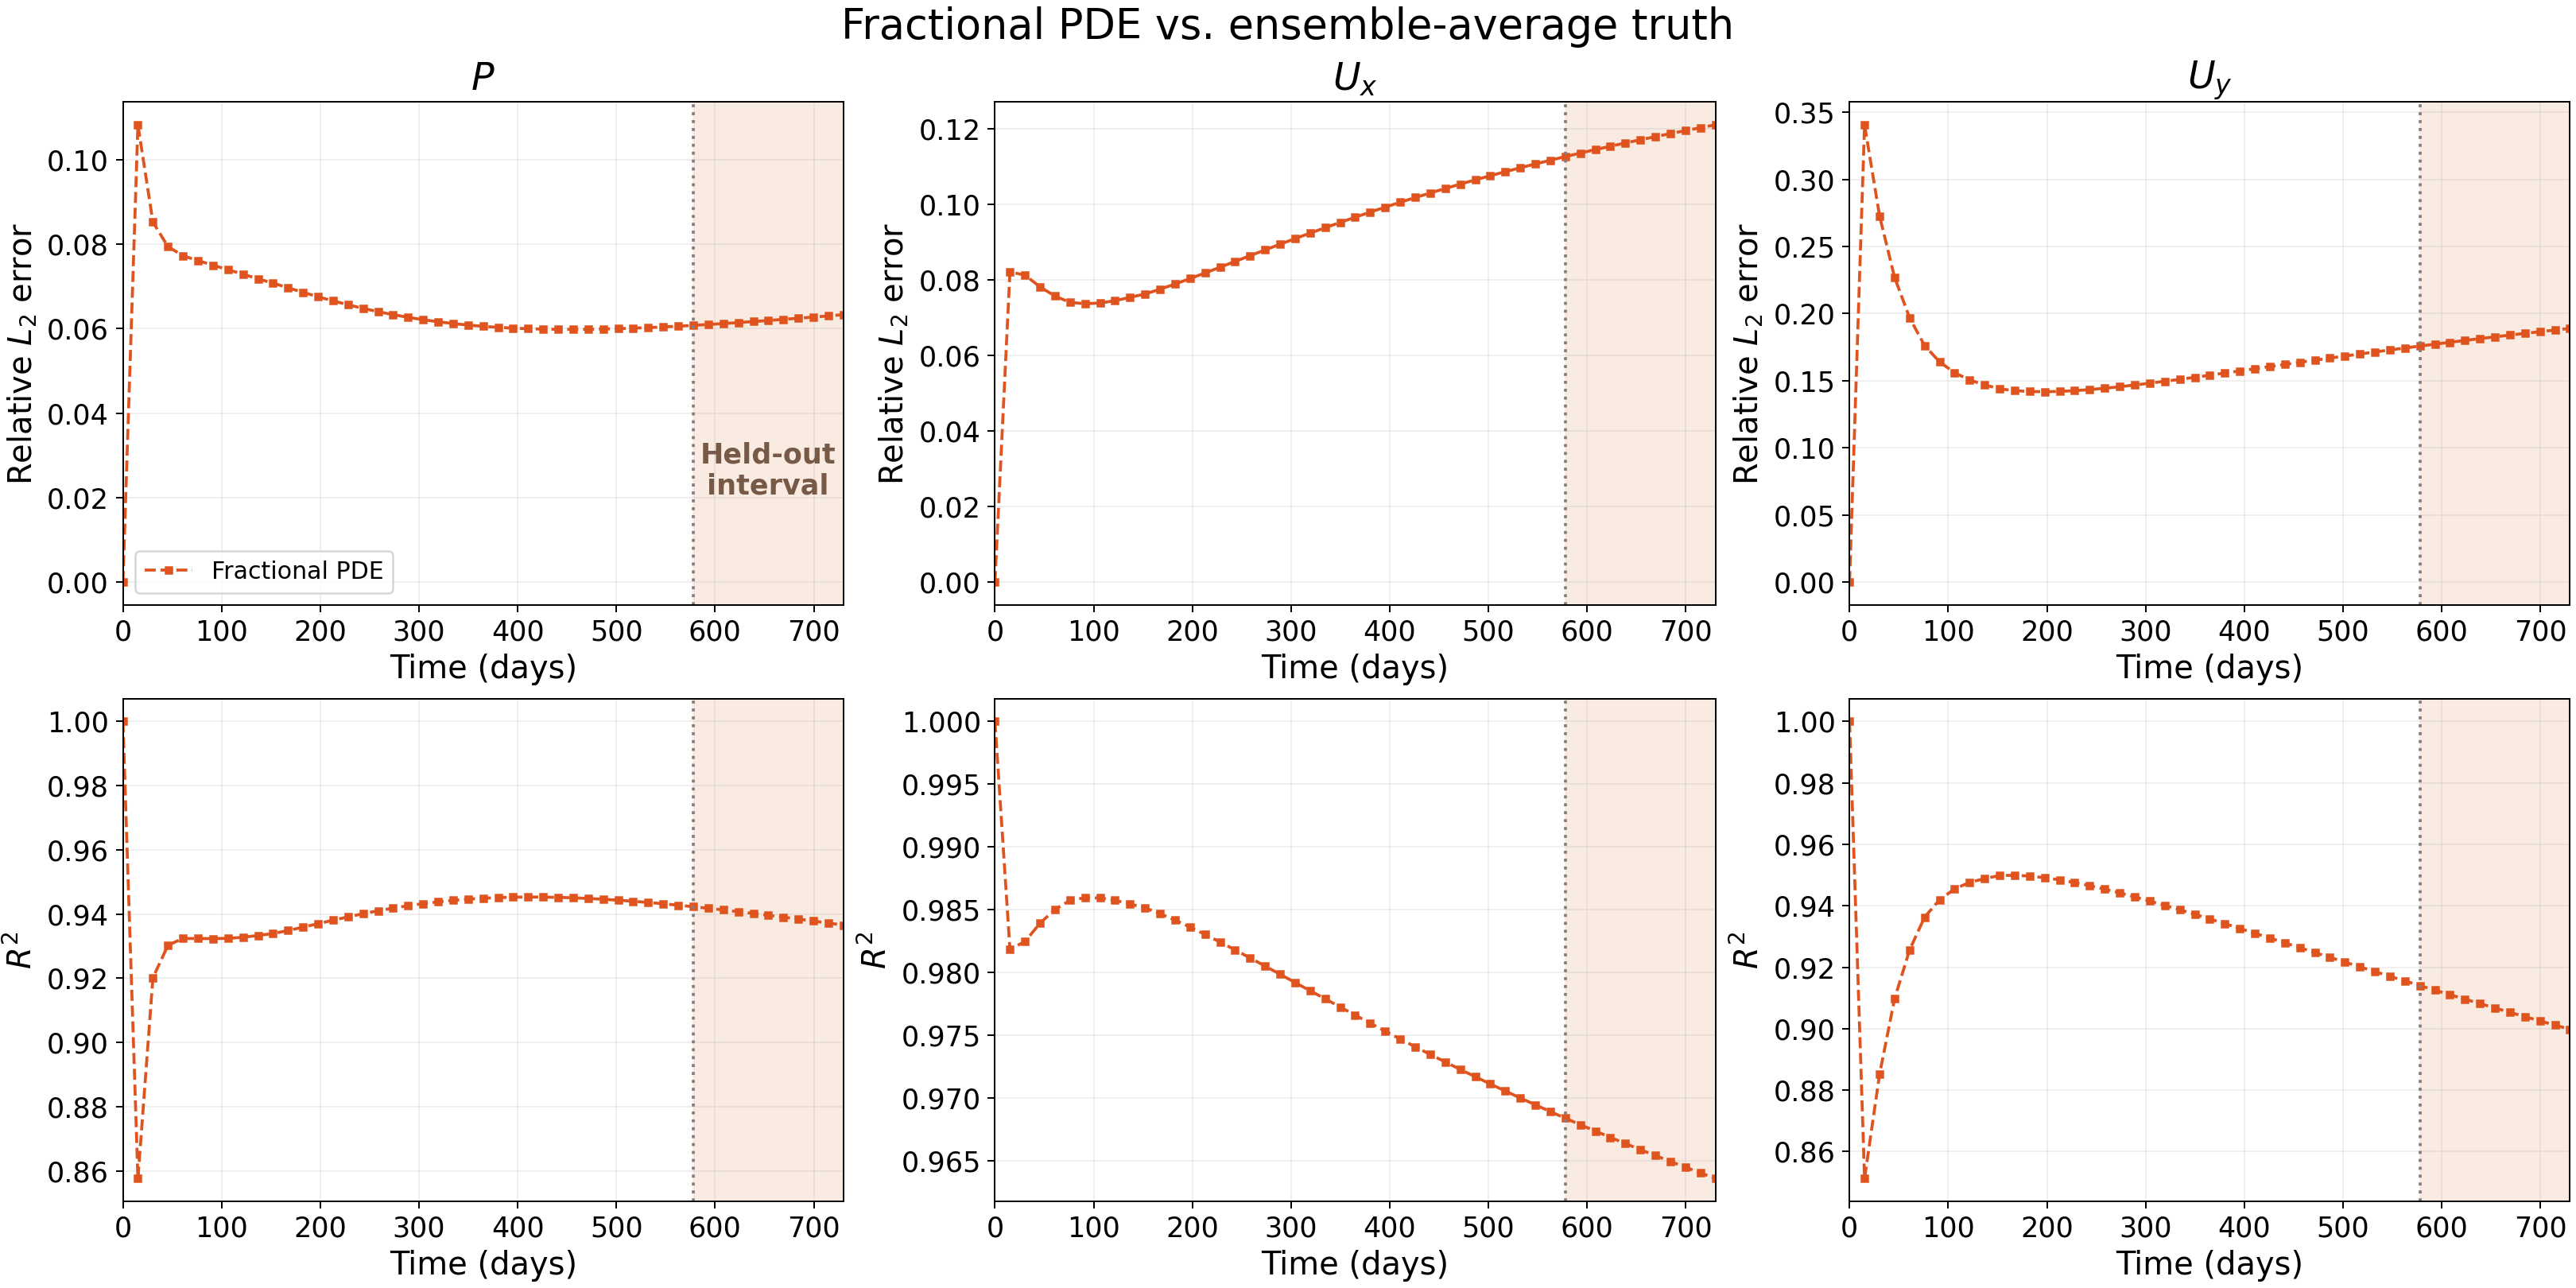

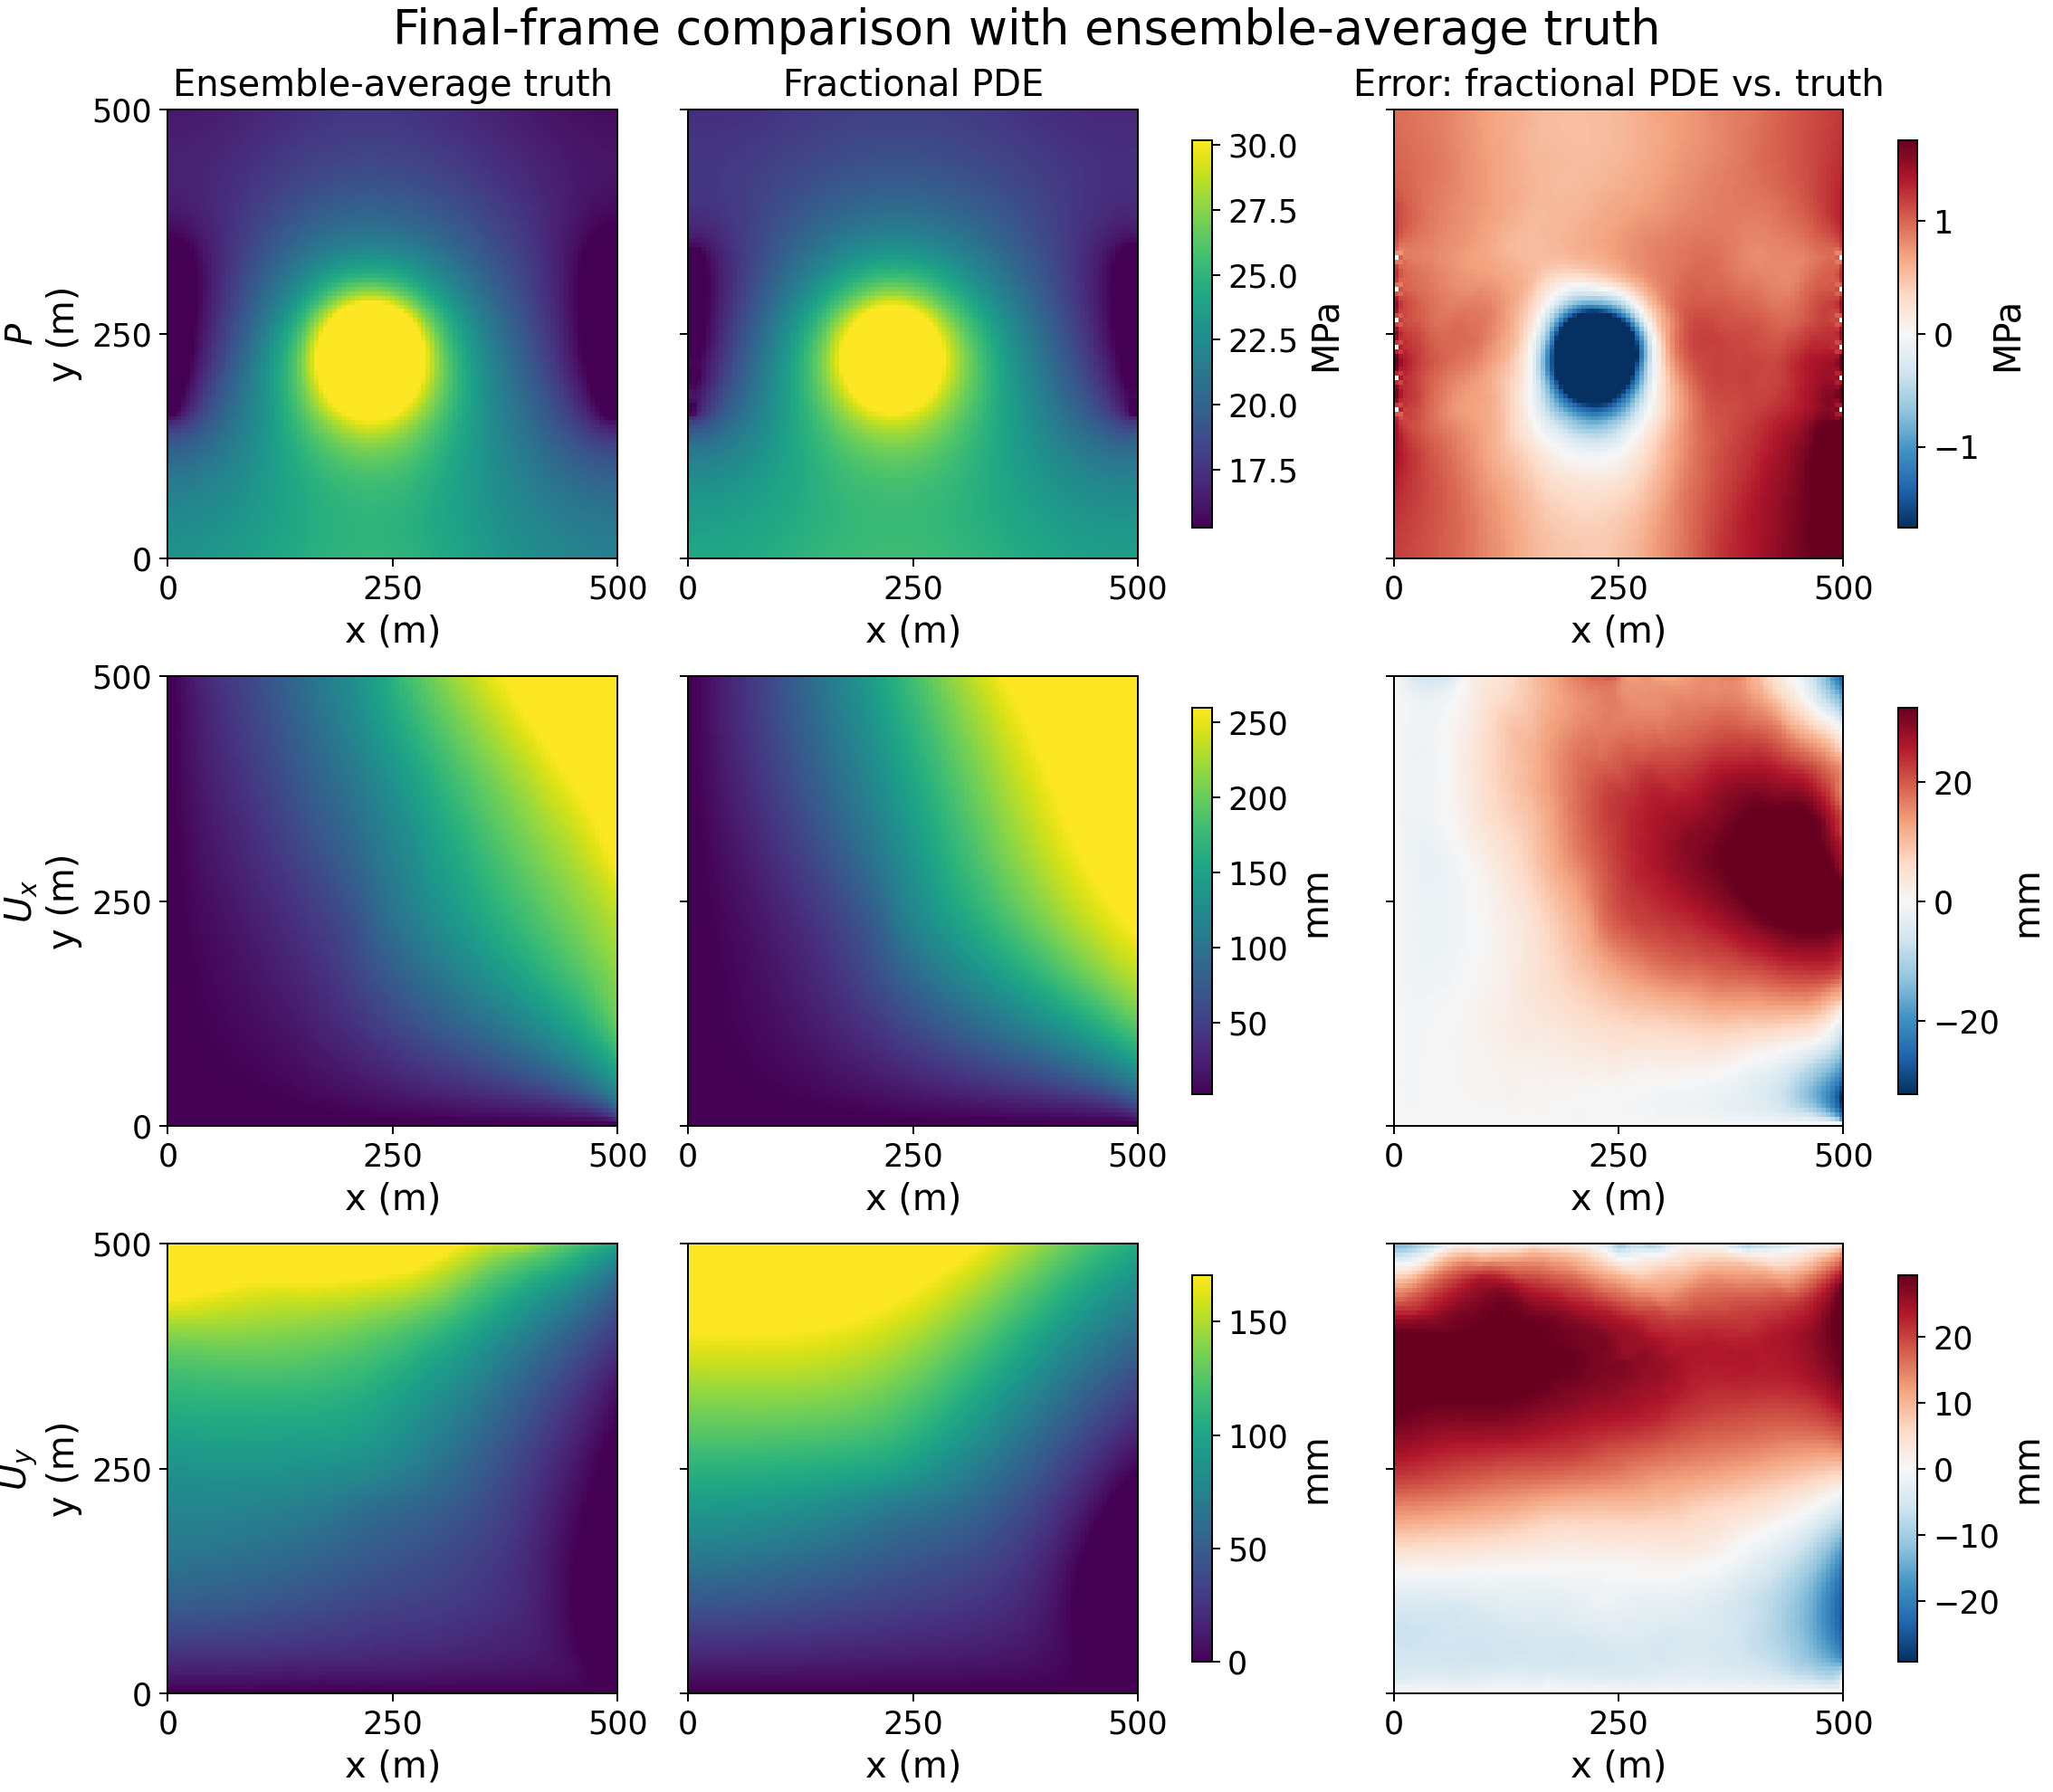

In [11]:
# *****
# Copyright Guodong Ren
# University of Southern California
# Contact: guodongr@usc.edu
# *****
# This notice covers release preparation and modifications, 2026-11-24.

if available:
    display(Image(filename=str(result_dir / "relative_L2_R2.png"), width=1100))
    display(Image(filename=str(result_dir / "last_frame_comparison.png"), width=870))